# Experimento comparativo: baseline naïve, Random Forest e LSTM

**TCC II: Previsão da Demanda Turística em Foz do Iguaçu**

Executa o experimento descrito na Seção 3.7 do TCC pelo próprio sistema: cada execução
passa pelo `TreinamentoService`, que pré-processa a série, treina, serializa o modelo,
prevê o conjunto de teste, calcula as métricas nos dois escopos e **grava tudo no banco**
(`tb_exp_execucoes`, `tb_exp_previsoes`, `tb_exp_metricas`; RF19). As execuções
aparecem depois na tela de Histórico.

**Desenho do experimento**

| Item | Definição |
|---|---|
| Teste | ano de 2025 inteiro (12 meses; 3 de alta temporada), usado uma única vez (RN04) |
| Treino | 25 meses com defasagens completas (bloco 1: 9 · bloco 2: 16) |
| Atributos | defasagens 1 a 3, mês em seno/cosseno, indicador de alta temporada |
| Ajuste de hiperparâmetros | busca em grade com `TimeSeriesSplit(4)` dentro do treino (RF14) |
| Sementes | 42 a 46: a semente do projeto (`config.SEED`) e as quatro seguintes |
| Resultado principal | semente 42, fixada antes do experimento; as demais medem a estabilidade |
| Significância | Diebold-Mariano com correção de Harvey, Leybourne e Newbold (RN08) |

O naïve sazonal é determinístico e roda uma única vez.

In [1]:
# Bibliotecas do Python
import json, os, sys, time
from pathlib import Path

# Pasta do projeto, para o notebook usar os módulos do sistema
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))

# Bibliotecas de cálculo, tabelas e gráficos
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

# Módulos do sistema
import config
from aplicacao.avaliacao import AvaliacaoService
from aplicacao.preprocessamento import PreProcessamentoService
from aplicacao.treinamento import TreinamentoService
from dominio.entidades import (EscopoAvaliacaoEnum as E, TipoMetricaEnum as M,
                               TipoModeloEnum as T)
from infraestrutura.modelos.lstm import LSTMModel
from infraestrutura.modelos.naive import NaiveSazonal
from infraestrutura.modelos.random_forest import RandomForestModel
from infraestrutura.repositorios.sqlite_repo import SqliteRepository

# Modo de conferência (TCC_RAPIDO=1): grade e sementes reduzidas, com banco e pasta temporários
# (TCC_BANCO e TCC_SAIDA), só para testar o notebook. A execução oficial roda sem essas variáveis.
RAPIDO = os.environ.get("TCC_RAPIDO") == "1"
# Pasta onde os gráficos e o resultado são gravados (docs/resultados, ou a indicada em TCC_SAIDA).
SAIDA = Path(os.environ.get("TCC_SAIDA") or RAIZ / "docs" / "resultados")
SAIDA.mkdir(parents=True, exist_ok=True)

# Cores e estilo dos gráficos.
TINTA, TINTA2, GRADE, AMBAR = "#0b0b0b", "#52514e", "#e1e0d9", "#eda100"
# Cor e marcador acompanham o modelo em todas as figuras (ordem categórica fixa).
COR = {"real": TINTA, "naive": "#2a78d6", "random_forest": "#eb6834", "lstm": "#1baf7a"}
MARCA = {"real": "o", "naive": "s", "random_forest": "^", "lstm": "D"}
ROTULO = {"real": "Valor real", "naive": "Naïve sazonal",
          "random_forest": "Random Forest", "lstm": "LSTM"}
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 10, "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA2,
    "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
    "lines.linewidth": 1.8, "lines.markersize": 5,
})
# Formata os números dos eixos com ponto de milhar; MESES dá os nomes curtos dos meses.
milhar = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

# Banco usado (o real, ou o indicado em TCC_BANCO) e a série mensal lida dele.
repo = SqliteRepository(os.environ.get("TCC_BANCO") or None)
serie = repo.carregar_serie()
# Dicionário que junta os resultados ao longo do notebook; no fim, vira o resultados.json.
RES = {}

## 1. Pré-processamento aplicado

In [2]:
# Pré-processamento pelo serviço do sistema: prepara a série (exclui a pandemia, trata ausentes e
# monta os atributos) e separa treino e teste. Também calcula, só no treino, os limites de valores
# atípicos pelo intervalo interquartil (IQR) e lista os meses fora deles. Resumo da Seção 5.2 do TCC.
pre = PreProcessamentoService()
preparada = pre.preparar(serie)
treino, teste = pre.dividir(preparada)
inferior, superior = PreProcessamentoService.limites_outliers(treino)
candidatos = [r.rotulo for r in treino.registros if not inferior <= r.desembarques <= superior]
linhas_treino = treino.com_atributos()
RES["preprocessamento"] = {
    **{k: (list(v) if isinstance(v, tuple) else v) for k, v in pre.relatorio.items() if k != "blocos"},
    "blocos": {str(k): v for k, v in pre.relatorio["blocos"].items()},
    "treino_por_bloco": {str(b): sum(1 for r in linhas_treino if r.bloco_temporal == b) for b in (1, 2)},
    "treino_inicio": linhas_treino[0].rotulo, "treino_fim": linhas_treino[-1].rotulo,
    "teste_inicio": teste.com_atributos()[0].rotulo, "teste_fim": teste.com_atributos()[-1].rotulo,
    "outlier_limite_inferior": inferior, "outlier_limite_superior": superior,
    "outlier_candidatos": candidatos,
    "atributos": PreProcessamentoService.nomes_atributos(preparada),
}
RES["preprocessamento"]

{'meses_brutos': 81,
 'meses_apos_corte': 43,
 'meses_interpolados': 0,
 'linhas_matriz': 37,
 'lags': [1, 2, 3],
 'treino': 25,
 'teste': 12,
 'blocos': {'1': 12, '2': 31},
 'treino_por_bloco': {'1': 9, '2': 16},
 'treino_inicio': '2019-06',
 'treino_fim': '2024-12',
 'teste_inicio': '2025-01',
 'teste_fim': '2025-12',
 'outlier_limite_inferior': 52543.75,
 'outlier_limite_superior': 115781.75,
 'outlier_candidatos': [],
 'atributos': ['lag_1',
  'lag_2',
  'lag_3',
  'mes_sen',
  'mes_cos',
  'fl_alta_temporada']}

## 2. Execuções (gravadas no banco)

In [3]:
# Fábrica de modelos: liga cada tipo de modelo à classe que o cria, como no sistema. No modo de
# conferência, a LSTM usa uma grade menor, para rodar rápido.
fabrica = {T.NAIVE: NaiveSazonal, T.RANDOM_FOREST: RandomForestModel, T.LSTM: LSTMModel}
if RAPIDO:
    fabrica[T.LSTM] = lambda semente: LSTMModel(semente=semente, n_particoes=2,
                                                grade={"unidades": [8], "dropout": [0.0]})
# Serviço de treinamento do sistema, gravando no banco escolhido. Os modelos treinados vão para a
# pasta padrão (dados/modelos) ou, no modo de conferência, para a pasta temporária.
pasta_modelos = Path(os.environ["TCC_SAIDA"]) / "modelos" if RAPIDO else None
servico = TreinamentoService(fabrica, repositorio=repo, pasta_modelos=pasta_modelos)
# Sementes 42 a 46 (duas no modo de conferência) e o plano das 11 execuções: o naïve uma vez e o
# Random Forest e a LSTM uma vez em cada semente.
SEMENTES = [config.SEED + i for i in range(2 if RAPIDO else 5)]
print("MODO DE CONFERÊNCIA" if RAPIDO else "EXECUÇÃO OFICIAL", "| banco:", repo.caminho, "| sementes:", SEMENTES)
plano = [(T.NAIVE, config.SEED)] + [(T.RANDOM_FOREST, s) for s in SEMENTES] + [(T.LSTM, s) for s in SEMENTES]

# Roda o plano. Cada volta chama executar() do serviço de treinamento, o mesmo que a tela Treinar
# usa: treina, prevê 2025, calcula as métricas e grava a execução no banco. Mostra o tempo e o MAPE
# de cada uma.
execucoes, duracoes = [], {}
for tipo, semente in plano:
    t0 = time.time()
    ex = servico.executar(serie, tipo, seed=semente)
    duracoes[(tipo.value, semente)] = time.time() - t0
    execucoes.append(ex)
    print(f"execução {ex.id:>3} | {tipo.value:<14} semente {semente} | {duracoes[(tipo.value, semente)]:6.1f}s | "
          f"MAPE global {ex.metrica(E.GLOBAL, M.MAPE):5.2f}% | alta {ex.metrica(E.ALTA_TEMPORADA, M.MAPE):5.2f}%")

# Retorna a execução da semente 42 (config.SEED) do tipo de modelo pedido.
def principal(tipo):
    return next(e for e in execucoes if e.tipo_modelo == tipo and e.semente_aleatoria == config.SEED)

# Execuções principais (semente 42) de cada modelo e o resumo de todas, guardados no resultado.
PRINCIPAL = {t.value: principal(t) for t in (T.NAIVE, T.RANDOM_FOREST, T.LSTM)}
RES["execucoes"] = [{"id": e.id, "modelo": e.tipo_modelo.value, "semente": e.semente_aleatoria,
                     "duracao_s": round(duracoes[(e.tipo_modelo.value, e.semente_aleatoria)], 1),
                     "hiperparametros": e.hiperparametros, "caminho_modelo": e.caminho_modelo,
                     "periodo_teste": e.periodo_teste, "janela": e.tamanho_janela_entrada,
                     "metricas": {f"{m.escopo_avaliacao.value}.{m.tipo_metrica.value}": m.valor_metrica
                                  for m in e.metricas}} for e in execucoes]
RES["ids_principais"] = {k: v.id for k, v in PRINCIPAL.items()}

EXECUÇÃO OFICIAL | banco: C:\tcc-previsao-demanda\dados\experimentos.db | sementes: [42, 43, 44, 45, 46]


execução   1 | naive          semente 42 |    2.9s | MAPE global 10.87% | alta 11.12%


execução   2 | random_forest  semente 42 |   25.0s | MAPE global  6.85% | alta  9.58%


execução   3 | random_forest  semente 43 |   14.9s | MAPE global  6.13% | alta  6.26%


execução   4 | random_forest  semente 44 |   15.2s | MAPE global  6.57% | alta  6.95%


execução   5 | random_forest  semente 45 |   14.7s | MAPE global  6.88% | alta  8.33%


... (2 outputs left out)

execução   8 | lstm           semente 43 |  561.3s | MAPE global  8.32% | alta  9.01%


execução   9 | lstm           semente 44 |  454.9s | MAPE global  8.31% | alta  9.40%


execução  10 | lstm           semente 45 |  465.4s | MAPE global  7.60% | alta  7.84%


execução  11 | lstm           semente 46 |  160.9s | MAPE global  8.35% | alta 11.49%


## 3. Métricas: resultado principal (semente 42)

In [4]:
# Tabela das métricas (MAE, RMSE e MAPE, no global e na alta temporada) das execuções principais.
linhas = []
for modelo, ex in PRINCIPAL.items():
    linha = {"modelo": ROTULO[modelo]}
    for esc in (E.GLOBAL, E.ALTA_TEMPORADA):
        for m in M:
            linha[f"{esc.value}.{m.value}"] = ex.metrica(esc, m)
    linhas.append(linha)
tab_metricas = pd.DataFrame(linhas).set_index("modelo")
RES["metricas_principais"] = {m: {k: float(v) for k, v in row.items()} for m, row in
                              zip(PRINCIPAL.keys(), tab_metricas.to_dict("records"))}
# Ganho relativo de cada modelo sobre o naïve (redução percentual do erro)
RES["reducao_vs_naive"] = {
    m: {k: float(100 * (1 - RES["metricas_principais"][m][k] / RES["metricas_principais"]["naive"][k]))
        for k in RES["metricas_principais"][m]} for m in ("random_forest", "lstm")}
tab_metricas.style.format({c: ("{:.2f}%" if c.endswith("MAPE") else "{:,.0f}") for c in tab_metricas.columns})

,global.MAE,global.RMSE,global.MAPE,alta_temporada.MAE,alta_temporada.RMSE,alta_temporada.MAPE
modelo,,,,,,
Naïve sazonal,"10,258","11,766",10.87%,"11,744","15,080",11.12%
Random Forest,"6,672","8,605",6.85%,"9,884","11,141",9.58%
LSTM,"8,446","9,461",9.01%,"8,554","9,564",8.25%


## 4. Previsões mês a mês

In [5]:
# Tabela mês a mês de 2025: real, previsto por cada modelo e erro percentual
# ((real - previsto) / real; positivo = subestimação).
prev = pd.DataFrame({"mes": [p.rotulo for p in PRINCIPAL["naive"].previsoes],
                     "alta": [p.alta_temporada for p in PRINCIPAL["naive"].previsoes],
                     "real": [p.valor_real for p in PRINCIPAL["naive"].previsoes]})
for modelo, ex in PRINCIPAL.items():
    prev[modelo] = [p.valor_previsto for p in ex.previsoes]
    prev[f"erro_pct_{modelo}"] = 100 * (prev["real"] - prev[modelo]) / prev["real"]
RES["previsoes"] = prev.to_dict("records")
# Viés: proporção de meses subestimados por modelo
RES["meses_subestimados"] = {m: int((prev[f"erro_pct_{m}"] > 0).sum()) for m in PRINCIPAL}
print("meses subestimados (de 12):", RES["meses_subestimados"])
prev.style.format({c: "{:,.0f}" for c in ["real", "naive", "random_forest", "lstm"]} |
                  {c: "{:+.1f}%" for c in prev.columns if c.startswith("erro_pct")})

meses subestimados (de 12): {'naive': 11, 'random_forest': 9, 'lstm': 12}


,mes,alta,real,naive,erro_pct_naive,random_forest,erro_pct_random_forest,lstm,erro_pct_lstm
0,2025-01,True,"105,033","94,457",+10.1%,"88,733",+15.5%,"95,469",+9.1%
1,2025-02,False,"89,051","84,653",+4.9%,"89,716",-0.7%,"88,675",+0.4%
2,2025-03,False,"85,772","82,127",+4.2%,"87,234",-1.7%,"74,803",+12.8%
3,2025-04,False,"82,034","72,418",+11.7%,"90,457",-10.3%,"72,002",+12.2%
4,2025-05,False,"83,427","71,474",+14.3%,"83,099",+0.4%,"72,508",+13.1%
5,2025-06,False,"82,391","70,038",+15.0%,"81,287",+1.3%,"78,723",+4.5%
6,2025-07,True,"88,891","89,678",-0.9%,"85,176",+4.2%,"86,009",+3.2%
7,2025-08,False,"96,301","87,099",+9.6%,"83,704",+13.1%,"88,770",+7.8%
8,2025-09,False,"89,102","80,694",+9.4%,"85,788",+3.7%,"82,292",+7.6%
9,2025-10,False,"101,975","86,588",+15.1%,"87,705",+14.0%,"86,070",+15.6%


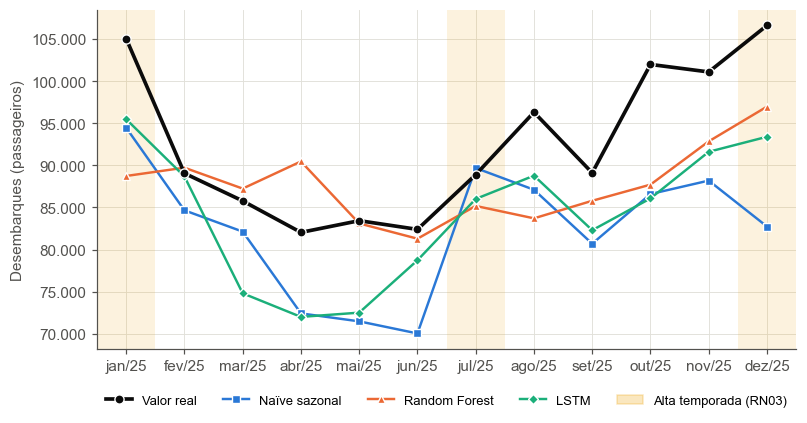

In [6]:
# Gráfico previsto × real de 2025; gravado como cap5_previsto_real.png.
fig, ax = plt.subplots(figsize=(8.2, 4.0))
x = np.arange(1, 13)
# Faixas da alta temporada (janeiro, julho e dezembro).
for m in (1, 7, 12):
    ax.axvspan(m - 0.5, m + 0.5, color=AMBAR, alpha=0.13, lw=0)
# Uma linha por série, com a cor e o marcador do modelo; o valor real fica mais grosso.
for serie_ in ("real", "naive", "random_forest", "lstm"):
    destaque = serie_ == "real"
    ax.plot(x, prev[serie_], color=COR[serie_], marker=MARCA[serie_],
            lw=2.4 if destaque else 1.6, markersize=6 if destaque else 5,
            markeredgecolor="white", markeredgewidth=0.9, zorder=4 if destaque else 3,
            label=ROTULO[serie_])
# Eixos, legenda (com a faixa da alta temporada) e gravação da figura.
ax.set_xticks(x, [f"{m}/25" for m in MESES])
ax.set_xlim(0.5, 12.5)
ax.yaxis.set_major_formatter(milhar)
ax.set_ylabel("Desembarques (passageiros)")
h, l = ax.get_legend_handles_labels()
h.append(Patch(color=AMBAR, alpha=0.25)); l.append("Alta temporada (RN03)")
ax.legend(h, l, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1), fontsize=8.5)
fig.savefig(SAIDA / "cap5_previsto_real.png")
plt.show()

## 5. Estabilidade entre sementes

In [7]:
# MAPE, MAE e RMSE de cada execução nos dois escopos e, para o Random Forest e a LSTM, a média,
# o desvio-padrão, o mínimo e o máximo do MAPE nas cinco sementes.
registros = []
for e in execucoes:
    for esc in (E.GLOBAL, E.ALTA_TEMPORADA):
        registros.append({"modelo": e.tipo_modelo.value, "semente": e.semente_aleatoria,
                          "escopo": esc.value, "MAPE": e.metrica(esc, M.MAPE),
                          "MAE": e.metrica(esc, M.MAE), "RMSE": e.metrica(esc, M.RMSE)})
sem = pd.DataFrame(registros)
resumo = sem[sem.modelo != "naive"].groupby(["modelo", "escopo"])["MAPE"].agg(["mean", "std", "min", "max"])
RES["sementes"] = {f"{m}.{e}": {k: float(v) for k, v in row.items()} for (m, e), row in resumo.iterrows()}
RES["sementes_detalhe"] = sem.to_dict("records")
resumo

mean       std       min        max
modelo        escopo                                                 
lstm          alta_temporada  9.197687  1.423335  7.837027  11.494407
              global          8.319223  0.500527  7.598986   9.013518
random_forest alta_temporada  7.665744  1.304099  6.263631   9.579572
              global          6.545689  0.329283  6.131123   6.878395

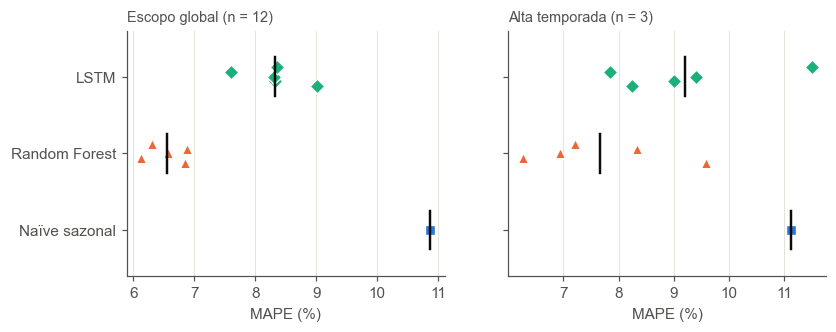

In [8]:
# Gráfico do MAPE de cada semente por modelo, nos dois escopos, com um traço na média. Os pontos
# do mesmo modelo são levemente espalhados na vertical para não ficarem um sobre o outro.
# Gravado como cap5_sementes.png.
fig, axs = plt.subplots(1, 2, figsize=(8.2, 2.9), sharey=True)
ordem = ["naive", "random_forest", "lstm"]
for ax, esc, titulo in zip(axs, ("global", "alta_temporada"), ("Escopo global (n = 12)", "Alta temporada (n = 3)")):
    for i, modelo in enumerate(ordem):
        v = sem[(sem.modelo == modelo) & (sem.escopo == esc)]["MAPE"].values
        jitter = np.linspace(-0.12, 0.12, len(v)) if len(v) > 1 else [0]
        ax.scatter(v, i + np.asarray(jitter), color=COR[modelo], marker=MARCA[modelo], s=46,
                   edgecolor="white", linewidth=0.9, zorder=3)
        ax.plot([v.mean(), v.mean()], [i - 0.25, i + 0.25], color=TINTA, lw=1.6, zorder=4)
    ax.set_title(titulo, fontsize=9.5, color=TINTA2, loc="left")
    ax.set_xlabel("MAPE (%)")
    ax.grid(axis="y", visible=False)
axs[0].set_yticks(range(3), [ROTULO[m] for m in ordem])
axs[0].set_ylim(-0.6, 2.6)
fig.savefig(SAIDA / "cap5_sementes.png")
plt.show()

## 6. Significância estatística: Diebold-Mariano (RF17, RN08)

Hipótese nula: os dois modelos têm a mesma acurácia esperada. Estatística negativa
indica que o **primeiro** modelo do par errou menos. Perda quadrática (principal) e
absoluta (sensibilidade). O escopo de alta temporada (n = 3) não comporta inferência
e é reportado apenas de forma descritiva (Seção 3.7 do TCC).

In [9]:
# Diebold-Mariano entre os pares de modelos (execuções principais), nos dois escopos e nas duas
# perdas. Como funciona: separa os erros dos dois modelos no escopo, chama a mesma função do
# sistema e marca como significativo só quando o teste é aplicável e o valor-p fica abaixo de 5%.
av = AvaliacaoService()
pares = [("random_forest", "naive"), ("lstm", "naive"), ("random_forest", "lstm")]
dm = []
for a, b in pares:
    for esc, filtro in (("global", lambda p: True), ("alta_temporada", lambda p: p.alta_temporada)):
        ea = [p.erro for p in PRINCIPAL[a].previsoes if filtro(p)]
        eb = [p.erro for p in PRINCIPAL[b].previsoes if filtro(p)]
        for perda in ("quadratica", "absoluta"):
            r = av.teste_diebold_mariano(ea, eb, perda=perda)
            dm.append({"par": f"{a} x {b}", "escopo": esc, "perda": perda, **r,
                       "significativo_5": bool(r["aplicavel"] and r["valor_p"] is not None and r["valor_p"] < 0.05)})
RES["diebold_mariano"] = dm
tab_dm = pd.DataFrame(dm)[["par", "escopo", "perda", "n", "estatistica", "valor_p", "aplicavel", "significativo_5"]]
tab_dm

,par,escopo,perda,n,estatistica,valor_p,aplicavel,significativo_5
0,random_forest x naive,global,quadratica,12,-1.435858,0.178864,True,False
1,random_forest x naive,global,absoluta,12,-1.982857,0.072912,True,False
2,random_forest x naive,alta_temporada,quadratica,3,-0.540280,0.643121,False,False
3,random_forest x naive,alta_temporada,absoluta,3,-0.298126,0.793727,False,False
4,lstm x naive,global,quadratica,12,-1.375085,0.196464,True,False
5,lstm x naive,global,absoluta,12,-1.334500,0.209006,True,False
6,lstm x naive,alta_temporada,quadratica,3,-1.046942,0.405001,False,False
7,lstm x naive,alta_temporada,absoluta,3,-0.831173,0.493305,False,False
8,random_forest x lstm,global,quadratica,12,-0.636564,0.537430,True,False
9,random_forest x lstm,global,absoluta,12,-1.229303,0.244606,True,False


In [10]:
# Robustez: o veredito RF x naïve e LSTM x naïve (global, perda quadrática) em cada semente.
# Como funciona: compara cada execução do RF e da LSTM com a execução do naïve.
naive = PRINCIPAL["naive"]
rob = []
for e in execucoes:
    if e.tipo_modelo == T.NAIVE:
        continue
    r = av.teste_diebold_mariano([p.erro for p in e.previsoes], [p.erro for p in naive.previsoes])
    rob.append({"modelo": e.tipo_modelo.value, "semente": e.semente_aleatoria,
                "estatistica": r["estatistica"], "valor_p": r["valor_p"]})
RES["diebold_mariano_por_semente"] = rob
pd.DataFrame(rob)

,modelo,semente,estatistica,valor_p
0,random_forest,42,-1.435858,0.178864
1,random_forest,43,-1.818014,0.096371
2,random_forest,44,-1.672410,0.122614
3,random_forest,45,-1.595237,0.138966
4,random_forest,46,-1.777707,0.103073
5,lstm,42,-1.375085,0.196464
6,lstm,43,-1.718472,0.113690
7,lstm,44,-1.834760,0.093705
8,lstm,45,-1.796166,0.099953
9,lstm,46,-1.635239,0.130264


## 7. Importância dos atributos no Random Forest (semente 42)

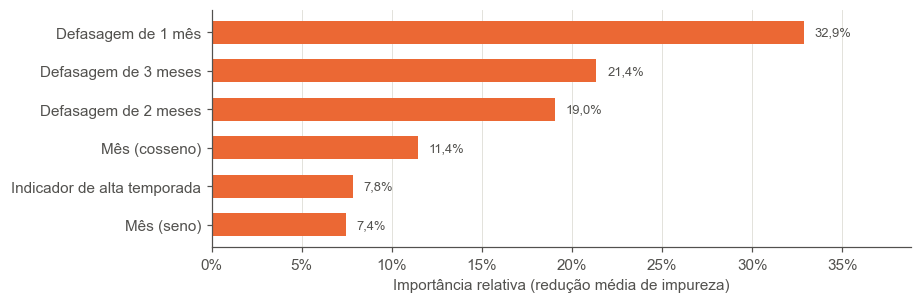

lag_1                0.328772
lag_3                0.213507
lag_2                0.190431
mes_cos              0.114473
fl_alta_temporada    0.078324
mes_sen              0.074493
dtype: float64

In [11]:
# Importância dos atributos no Random Forest da semente 42: recarrega o modelo salvo e lê a
# redução média de impureza de cada atributo.
rf = RandomForestModel()
rf.carregar(PRINCIPAL["random_forest"].caminho_modelo)
imp = pd.Series(rf.importancia_atributos()).sort_values()
RES["importancia_rf"] = {k: float(v) for k, v in imp.sort_values(ascending=False).items()}
# Nomes dos atributos no gráfico.
NOMES = {"lag_1": "Defasagem de 1 mês", "lag_2": "Defasagem de 2 meses", "lag_3": "Defasagem de 3 meses",
         "mes_sen": "Mês (seno)", "mes_cos": "Mês (cosseno)", "fl_alta_temporada": "Indicador de alta temporada"}
# Gráfico de barras com o percentual de cada atributo; gravado como cap5_importancia_rf.png.
fig, ax = plt.subplots(figsize=(8.2, 2.8))
ax.barh([NOMES[k] for k in imp.index], imp.values, color=COR["random_forest"], height=0.6)
for i, v in enumerate(imp.values):
    ax.text(v + 0.006, i, f"{100 * v:.1f}%".replace(".", ","), va="center", fontsize=8.5, color=TINTA2)
ax.set_xlabel("Importância relativa (redução média de impureza)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{100 * v:.0f}%"))
ax.grid(axis="y", visible=False)
ax.set_xlim(0, imp.max() * 1.18)
fig.savefig(SAIDA / "cap5_importancia_rf.png")
plt.show()
imp.sort_values(ascending=False)

In [ ]:
# Importância por permutação, baseada na proposta de Breiman (2001, Seção 10), pela implementação do
# scikit-learn, sobre o treino e o teste e com o MAE como medida de erro (e não sobre as observações
# fora da amostra bootstrap, como no artigo). Compara com a redução de impureza acima (Seção 5.6 do TCC).
from sklearn.inspection import permutation_importance

# Retorna, para cada atributo, quanto o MAE aumenta quando os valores dele são embaralhados e a
# participação desse aumento no total. Como funciona: embaralha cada atributo 100 vezes
# (permutation_importance); o atributo que, embaralhado, não piora o erro conta como zero.
def importancia_permutacao(modelo, serie_aval, repeticoes=100):
    linhas = serie_aval.com_atributos()
    X = np.array([[r.atributos[c] for c in modelo._colunas] for r in linhas])
    y = np.array([r.desembarques for r in linhas])
    r = permutation_importance(modelo._modelo, X, y, scoring="neg_mean_absolute_error",
                               n_repeats=repeticoes, random_state=42)
    positivos = np.clip(r.importances_mean, 0, None)   # embaralhar sem piorar o erro conta como zero
    return {c: {"aumento_mae": float(v), "participacao": float(p / positivos.sum())}
            for c, v, p in zip(modelo._colunas, r.importances_mean, positivos)}

# Calcula a importância por permutação de cada Random Forest (cinco sementes), no treino e no
# teste, e mostra a da semente 42 ao lado da redução de impureza, em percentual.
RES["importancia_permutacao"] = {}
for ex in execucoes:
    if ex.tipo_modelo != T.RANDOM_FOREST:
        continue
    modelo = RandomForestModel(semente=ex.semente_aleatoria)
    modelo.carregar(ex.caminho_modelo)
    RES["importancia_permutacao"][str(ex.semente_aleatoria)] = {
        "impureza": {c: float(v) for c, v in zip(modelo._colunas, modelo._modelo.feature_importances_)},
        "treino": importancia_permutacao(modelo, treino),
        "teste": importancia_permutacao(modelo, teste)}
p42 = RES["importancia_permutacao"][str(config.SEED)]
pd.DataFrame({"impureza": p42["impureza"],
              "permutação no treino": {c: v["participacao"] for c, v in p42["treino"].items()},
              "permutação no teste": {c: v["participacao"] for c, v in p42["teste"].items()}}).mul(100).round(1)

In [12]:
# Retorna uma cópia dos resultados que o json consegue gravar. Como funciona: percorre
# dicionários e listas, passa as chaves para texto e troca os números e os valores lógicos do
# numpy pelos tipos comuns do Python (float, int e bool).
def limpar(o):
    if isinstance(o, dict): return {str(k): limpar(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [limpar(v) for v in o]
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
# Grava os resultados em resultados.json, na pasta de saída, lista os gráficos e mostra quantas
# execuções há no banco.
(SAIDA / "resultados.json").write_text(json.dumps(limpar(RES), ensure_ascii=False, indent=1), encoding="utf-8")
print("gravado:", sorted(p.name for p in SAIDA.glob("cap5_*.png")), "+ resultados.json")
print("execuções no banco:", len(repo.listar_execucoes()))

gravado: ['cap5_acf.png', 'cap5_decomposicao.png', 'cap5_importancia_rf.png', 'cap5_perfil_sazonal.png', 'cap5_previsto_real.png', 'cap5_sementes.png', 'cap5_serie_historica.png'] + resultados.json
execuções no banco: 11
